# 30. Decorrelation Analysis Continuous

Now it's time to find out which factors are causing these decorrelation scale results.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from pathlib import Path
import warnings

import sys
# Ensure local scripts are importable
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths

warnings.filterwarnings('ignore')

# Configure plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


## Load Data

In [10]:
# Load Decorrelation scales
dec_df = pd.read_csv(ProjectPaths.DECORRELATION_SCALE_FILE)
dec_df['Station_ID'] = dec_df['Station_ID'].astype(str).str.zfill(8)

# Load merged datasets to get depths
if ProjectPaths.MERGED_DATA_FILE.suffix == '.feather':
    merged_gdf = pd.read_feather(ProjectPaths.MERGED_DATA_FILE)
else:
    merged_gdf = pd.read_csv(ProjectPaths.MERGED_DATA_FILE)
    
# Convert depth to numeric - Crucial fix for 'TypeError: >= not supported between instances of str and float'
merged_gdf['depth'] = pd.to_numeric(merged_gdf['depth'], errors='coerce')

# Extract max depth for each station
max_depths = merged_gdf.groupby('zettaicode')['depth'].max().reset_index()
max_depths['zettaicode'] = max_depths['zettaicode'].astype(str).str.zfill(8)

# Merge datasets
analysis_df = dec_df.merge(max_depths, left_on='Station_ID', right_on='zettaicode', how='inner')
display(analysis_df.head())


,Station_ID,Decorrelation_Scale_km,Amplitude_A,Offset_B,dx_param,R_squared,r_crit,n_neighbors_100km,zettaicode,depth
0,00000272,0.993078,1.023714,-0.023714,1.176791,0.574281,0.478511,28,00000272,15.3
1,00000275,10.372869,1.023110,-0.023110,12.022615,0.529142,0.462892,30,00000275,23.0
2,00002725,9.479547,0.950292,0.049708,10.079030,0.644923,0.442072,33,00002725,20.6
3,00002737,6.222165,0.901332,0.098668,6.334103,0.412775,0.442072,33,00002737,18.1
4,00002744,6.459212,0.882845,0.117155,6.397771,0.406290,0.435728,34,00002744,35.1


### Max depths of station

Correlation between Decorrelation Scale and Max Depth: 0.3154


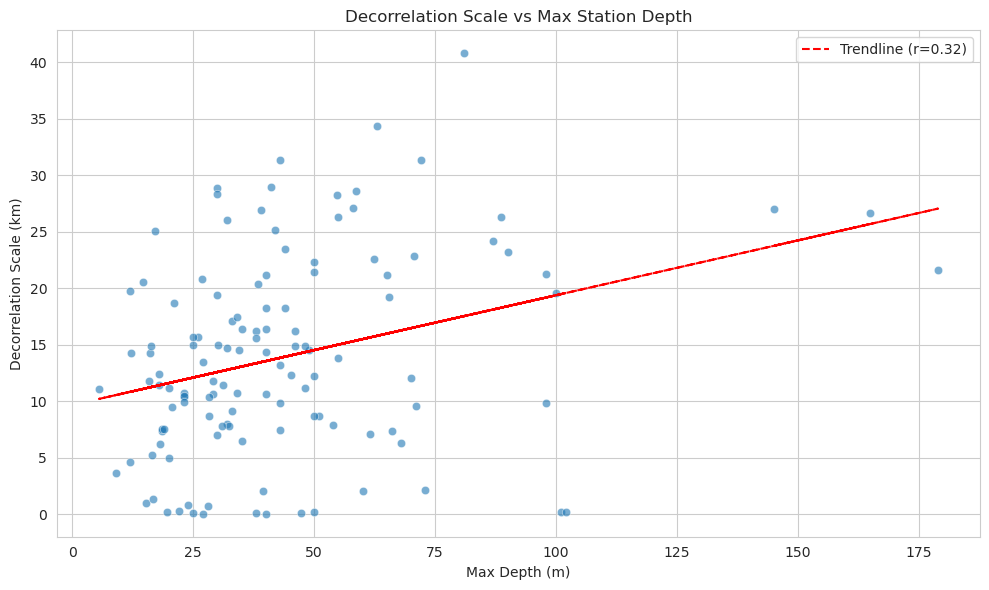

In [11]:
# Calculate correlation
analysis_df_clean = analysis_df.dropna(subset=['depth', 'Decorrelation_Scale_km'])
correlation = analysis_df_clean['Decorrelation_Scale_km'].corr(analysis_df_clean['depth'])
print(f"Correlation between Decorrelation Scale and Max Depth: {correlation:.4f}")

# Plot scatter plot
plt.figure()
sns.scatterplot(data=analysis_df_clean, x='depth', y='Decorrelation_Scale_km', alpha=0.6)

# Add trendline
if len(analysis_df_clean) > 1:
    m, b = np.polyfit(analysis_df_clean['depth'], analysis_df_clean['Decorrelation_Scale_km'], 1)
    plt.plot(analysis_df_clean['depth'], m * analysis_df_clean['depth'] + b, color='red', linestyle='--', label=f'Trendline (r={correlation:.2f})')

plt.title('Decorrelation Scale vs Max Station Depth')
plt.xlabel('Max Depth (m)')
plt.ylabel('Decorrelation Scale (km)')
plt.legend()
plt.tight_layout()
plt.show()


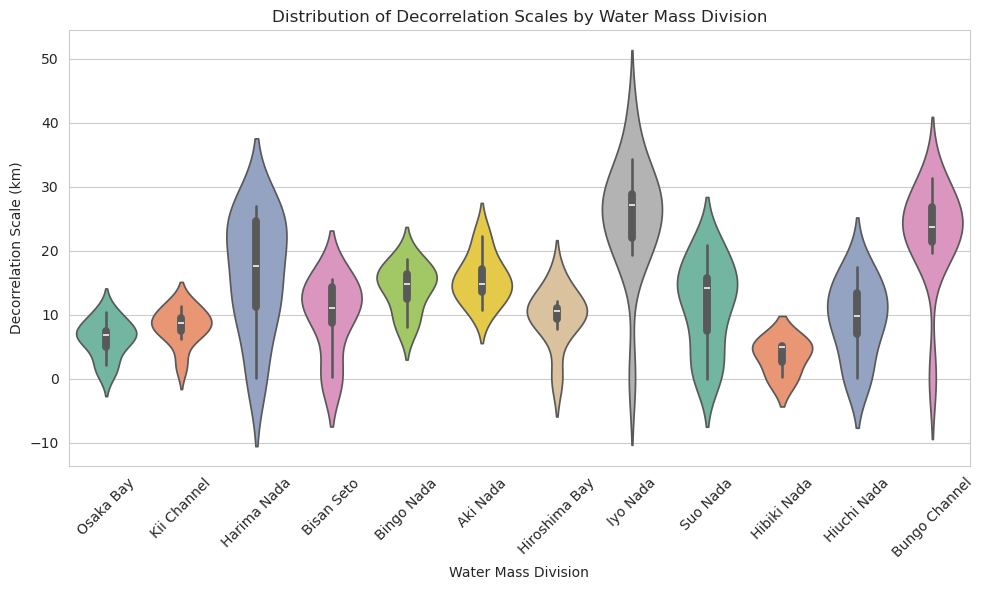

In [12]:
# Extract the 'division' (water mass) for each station from the original dataset
station_divisions = merged_gdf.groupby('zettaicode')['division'].first().reset_index()
station_divisions['zettaicode'] = station_divisions['zettaicode'].astype(str).str.zfill(8)

# Merge the division data into the cleaned analysis dataframe
df_violin = analysis_df_clean.merge(station_divisions, on='zettaicode', how='left')

# Drop any rows that couldn't be mapped to a division
df_violin = df_violin.dropna(subset=['division', 'Decorrelation_Scale_km'])

# Plot violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df_violin, 
    x='division', 
    y='Decorrelation_Scale_km', 
    hue='division',      
    palette='Set2',
    legend=False         
)

# Formatting
plt.title('Distribution of Decorrelation Scales by Water Mass Division')
plt.xlabel('Water Mass Division')
plt.ylabel('Decorrelation Scale (km)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Correlation between Hypoxia Frequency and Decorrelation Scale: -0.1513 (p-value: 0.0935 -> Not Significant)


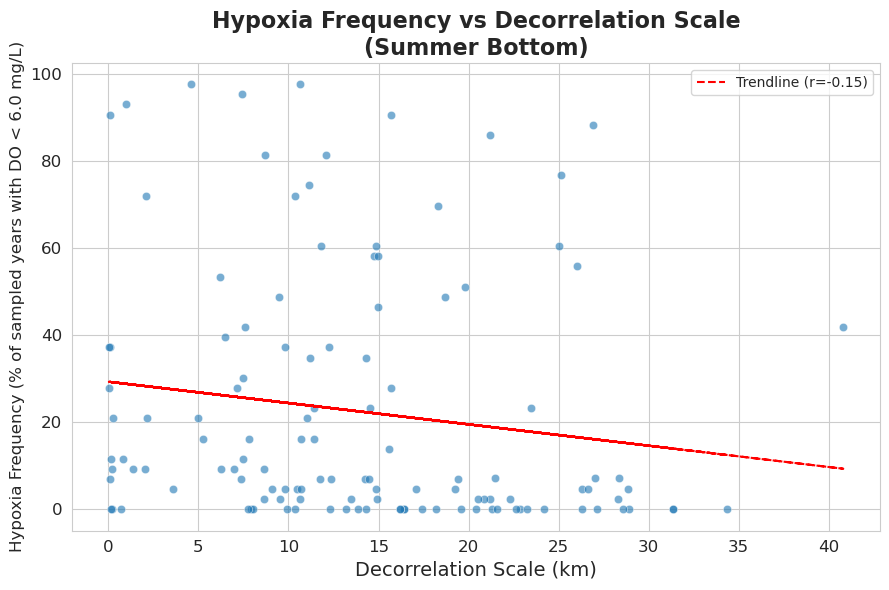

In [18]:
# Calculate Hypoxia Frequency vs Decorrelation Scale

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.stats import pearsonr

# 1. Filter the merged dataset for Summer Bottom layer (consistent with pipeline Stage 1.5)
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') & 
    (merged_gdf['saisuipoin'] == 2)
].copy()
summer_bottom_df['do_'] = pd.to_numeric(summer_bottom_df['do_'], errors='coerce')

# 2. Extract hypoxia frequency based on Stage 1.1 (04_Hypoxia_Mapping.ipynb)
hypoxia_threshold = 6.0  # Defined as 2.0 mg/L in Stage 1.1 

# Count total strictly unique sampled years per station
station_total_years = summer_bottom_df.groupby('zettaicode')['year'].nunique().reset_index(name='total_sampled_years')

# Count years with at least one hypoxia event per station
hypoxia_events = summer_bottom_df[summer_bottom_df['do_'] < hypoxia_threshold]
station_hypoxia_years = hypoxia_events.groupby('zettaicode')['year'].nunique().reset_index(name='hypoxia_years')

# Compute hypoxia frequency percentage
hypoxia_stats = pd.merge(station_total_years, station_hypoxia_years, on='zettaicode', how='left')
hypoxia_stats['hypoxia_years'] = hypoxia_stats['hypoxia_years'].fillna(0)
hypoxia_stats['hypoxia_frequency'] = (hypoxia_stats['hypoxia_years'] / hypoxia_stats['total_sampled_years']) * 100
hypoxia_stats['zettaicode'] = hypoxia_stats['zettaicode'].astype(str).str.zfill(8)

# 3. Merge with the previously loaded decorrelation analysis dataframe (analysis_df)
hypoxia_analysis_df = analysis_df.merge(hypoxia_stats, left_on='Station_ID', right_on='zettaicode', how='inner')
plot_df = hypoxia_analysis_df.dropna(subset=['hypoxia_frequency', 'Decorrelation_Scale_km'])
# Example: Only keep stations with at least 10 years of data
plot_df = plot_df[plot_df['total_sampled_years'] >= 15]

# Calculate Pearson correlation and p-value for significance
correlation_hypoxia, p_value = pearsonr(plot_df['Decorrelation_Scale_km'], plot_df['hypoxia_frequency'])
significance = "Significant" if p_value < 0.05 else "Not Significant"

print(f"Correlation between Hypoxia Frequency and Decorrelation Scale: {correlation_hypoxia:.4f} (p-value: {p_value:.4f} -> {significance})")

# 4. Generate Plot
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x='Decorrelation_Scale_km', y='hypoxia_frequency', alpha=0.6)

# Add trendline
if len(plot_df) > 1:
    m, b = np.polyfit(plot_df['Decorrelation_Scale_km'], plot_df['hypoxia_frequency'], 1)
    plt.plot(plot_df['Decorrelation_Scale_km'], m * plot_df['Decorrelation_Scale_km'] + b, color='red', linestyle='--', label=f'Trendline (r={correlation_hypoxia:.2f})')

plt.title('Hypoxia Frequency vs Decorrelation Scale\n(Summer Bottom)', fontsize=16, fontweight='bold')
plt.xlabel('Decorrelation Scale (km)', fontsize=14)
plt.ylabel('Hypoxia Frequency (% of sampled years with DO < 6.0 mg/L)', fontsize=12)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.legend()
plt.tight_layout()
plt.show()